# 01 — Exploratory data analysis

Goal: understand what one row of the data means and what's missing or dirty, **before** any modeling.
No features, no models here — just looking.

By the end you should be able to answer the questions in the last cell without scrolling back up.

In [1]:
import sys
sys.path.insert(0, "../src")  # lets us import our own code from src/

import matplotlib.pyplot as plt
import pandas as pd

from data_loading import load_matches, load_players

pd.set_option("display.max_columns", 60)
BLUE = "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.axisbelow": True})

df = load_matches()      # DataFrame: one row per match
players = load_players()
df.shape                 # (rows, columns)

(46964, 52)

### pandas cheat sheet (every idiom used below)

| Code | Meaning |
|---|---|
| `df.col` or `df["col"]` | one column (a *Series*). Use the bracket form when the name clashes with a method, e.g. `df["round"]` |
| `df.col == "x"` | a True/False Series, one value per row — a **boolean mask** |
| `df[mask]` | keep only rows where the mask is True. Combine masks with `&` (and) / `\|` (or), each in parentheses |
| `df.loc[mask, "col"]` | rows by mask, then one column |
| `.iloc[0]`, `.iloc[-1]` | rows by *position* (first, last) rather than by label |
| `series.mean()` on a True/False Series | fraction of True values — how we get every "% of matches" number |
| `df.groupby(key).size()` | count rows per group; `.groupby(key).mean()` averages per group |
| `df.col.dt.year` | the year part of a datetime column |
| `df.isna()` | True where a value is missing (NaN) |
| `df.dropna(subset=[...])` | drop rows missing any of those columns |
| `pd.concat([a, b])` | stack two Series/DataFrames end to end |
| `.value_counts()` | how many times each distinct value appears |

## 1. What is one row?

One row = **one completed (or abandoned) singles match**, written from the winner's point of view.
Here's the 2026 Roland Garros final, turned sideways so every column is visible:

In [2]:
# Two masks combined with &, then .iloc[-1] = the last (most recent) RG final.
# .to_frame() turns the single row into a one-column table so all 51 fields print vertically.
df[(df.tourney_name == "Roland Garros") & (df["round"] == "F")].iloc[-1].to_frame("value")

,value
tourney_id,2026-520
tourney_name,Roland Garros
surface,Clay
draw_size,128
tourney_level,G
tourney_date,2026-05-25 00:00:00
match_num,226
winner_id,100644
winner_seed,2.0
winner_entry,NaN


The 51 raw columns fall into a few groups:

| Group | Columns | Known **before** the match? |
|---|---|---|
| Tournament | `tourney_id, tourney_name, surface, draw_size, tourney_level, tourney_date, best_of, round, match_num` | ✅ yes |
| Player info (×2: `winner_*`, `loser_*`) | `id, name, seed, entry, hand, ht, ioc, age` | ✅ yes |
| Ranking (×2) | `winner_rank, winner_rank_points, loser_rank, loser_rank_points` | ✅ yes (ranking as of the tournament start) |
| Outcome | `score, minutes` | ❌ no — this *is* the result |
| Match stats (×2: `w_*`, `l_*`) | `ace, df, svpt, 1stIn, 1stWon, 2ndWon, SvGms, bpSaved, bpFaced` | ❌ no — counted during the match |

**This table is the most important thing in the notebook.** Anything in the ❌ rows is *leakage* if you
feed it to a model for the same match — the winner almost always has more aces and break points saved,
so the model would "predict" the result by reading the result. Those columns are only usable as
*historical averages from earlier matches* (that's Phase 2).

The second trap is the column *names*: `winner_rank` vs `loser_rank` already tells you who won.
Phase 2 shuffles each match into a random `player_1` / `player_2` orientation to fix that.

Codes you'll see:
- `tourney_level`: **G** = Grand Slam, **M** = Masters 1000, **A** = other tour events (250/500), **F** = Tour Finals,
  **D** = Davis Cup, **O** = Olympics
- `round`: R128 … R16, QF, SF, F; **RR** = round robin (Tour Finals, United Cup/ATP Cup, Davis Cup group stage); **BR** = bronze medal match (Olympics)
- `winner_entry` / `loser_entry`: blank = direct entry, **Q** = qualifier, **WC** = wildcard, **LL** = lucky loser, **PR** = protected ranking, **SE** = special exempt, **Alt/ALT** = alternate (same thing, inconsistent case)

## 2. How much data, and what kind?

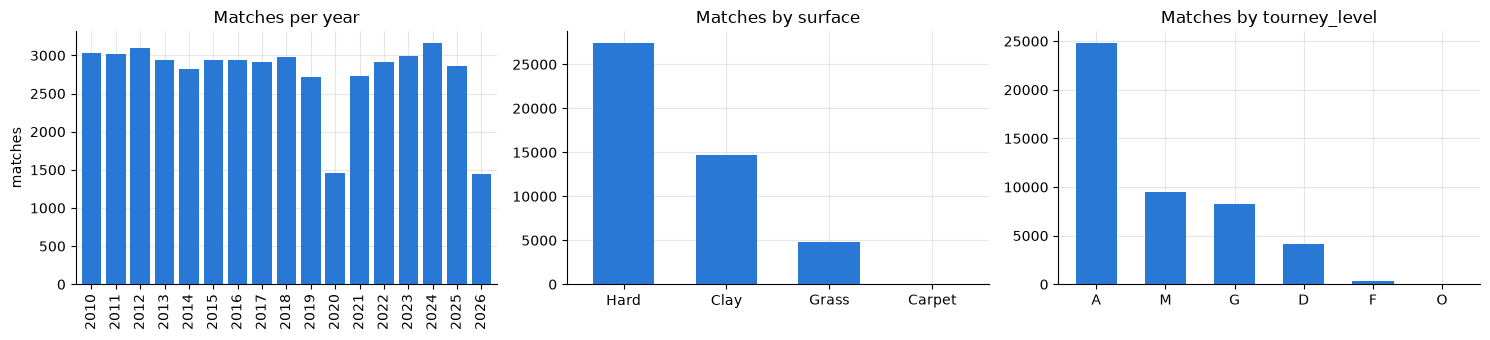

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))  # one figure, three side-by-side charts

# Group rows by year, count rows per group, draw as bars
df.groupby(df.tourney_date.dt.year).size().plot.bar(ax=axes[0], color=BLUE, width=0.8)
axes[0].set(title="Matches per year", xlabel="", ylabel="matches")

df.surface.value_counts().plot.bar(ax=axes[1], color=BLUE, width=0.6)
axes[1].set(title="Matches by surface", xlabel="")

df.tourney_level.value_counts().plot.bar(ax=axes[2], color=BLUE, width=0.6)
axes[2].set(title="Matches by tourney_level", xlabel="")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)
axes[0].tick_params(axis="x", rotation=90)
plt.tight_layout()

Things to notice:
- **2020 is about half a normal year** (COVID suspension). **2026 is partial** — the data snapshot stops after Roland Garros.
- **Hard courts dominate** (~58%), clay ~31%, grass only ~10%. Grass has the least data, so grass-specific stats (surface Elo) will be the noisiest.
- **Carpet** (66 matches) is a surface that's been phased out of the tour. **Davis Cup (D)** is ~9% of matches and is played under different conditions (home crowds, team format, often lower-ranked players).

## 3. Rankings — the obvious signal

Lower rank number = better player. How often does the better-ranked player win?
This is the **naive baseline** every model in Phase 3+ has to beat.

In [4]:
ranked = df.dropna(subset=["winner_rank", "loser_rank"])  # only matches where both players have a rank
fav_won = ranked.winner_rank < ranked.loser_rank          # True when the winner had the lower (better) rank number
# fav_won.mean() = fraction of True = how often the favourite won
print(f"Both players ranked: {len(ranked):,} of {len(df):,} matches ({len(ranked)/len(df):.1%})")
print(f"Better-ranked player won: {fav_won.mean():.1%}")

Both players ranked: 46,045 of 46,964 matches (98.0%)
Better-ranked player won: 65.5%


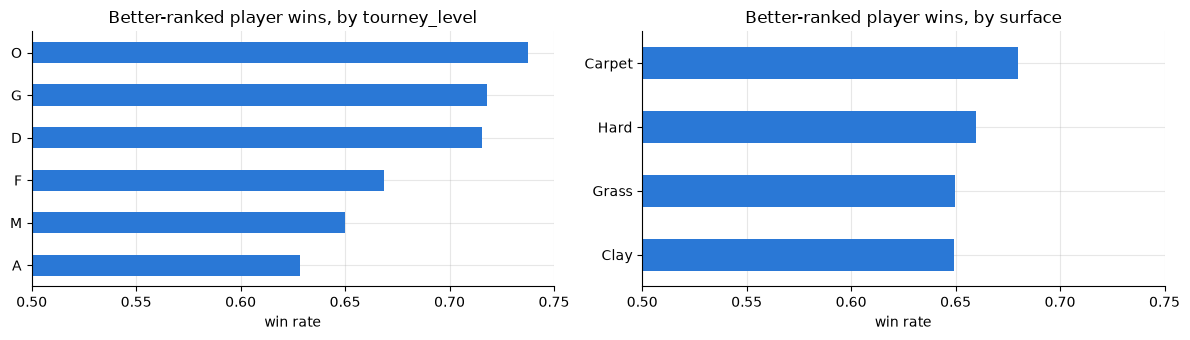

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))

# Same win rate, split per tourney_level (fav_won and ranked share row labels, so pandas lines them up)
fav_won.groupby(ranked.tourney_level).mean().sort_values().plot.barh(ax=axes[0], color=BLUE)
axes[0].set(title="Better-ranked player wins, by tourney_level", xlabel="win rate", ylabel="", xlim=(0.5, 0.75))

fav_won.groupby(ranked.surface).mean().sort_values().plot.barh(ax=axes[1], color=BLUE)
axes[1].set(title="Better-ranked player wins, by surface", xlabel="win rate", ylabel="", xlim=(0.5, 0.75))
plt.tight_layout()

Grand Slams (~72%) and the Olympics are the most predictable — best-of-5 gives the better player time to recover.
Regular tour events (`A`, ~63%) are the least. Davis Cup looks predictable (~72%) partly because of lopsided ties between
small tennis nations, *and* because this chart only counts matches where both players are ranked — many Davis Cup players
are unranked and silently drop out. **How you handle missing values can change your conclusions.**

By surface the differences are small (~65-66%); Carpet's higher bar is only 66 matches, so ignore it.

The x-axis starts at 50% — a coin flip — on purpose: that's the floor for any predictor.

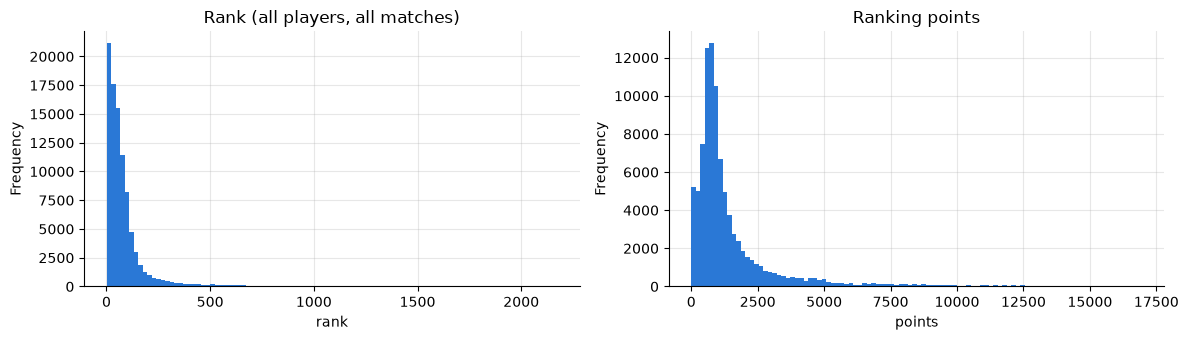

In [6]:
# Rank is very skewed: most match appearances are by top-150 players, with a long tail out past 2000.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
# Stack winners' and losers' ranks into one Series so every player appearance counts once
pd.concat([df.winner_rank, df.loser_rank]).plot.hist(bins=100, ax=axes[0], color=BLUE)
axes[0].set(title="Rank (all players, all matches)", xlabel="rank")
pd.concat([df.winner_rank_points, df.loser_rank_points]).plot.hist(bins=100, ax=axes[1], color=BLUE)
axes[1].set(title="Ranking points", xlabel="points")
plt.tight_layout()

Both are heavily right-skewed. The difference between rank 1 and rank 10 matters far more than between
rank 201 and rank 210 — worth remembering when we turn ranks into features (log-rank or rank *points*
often behave better than raw rank).

## 4. What's missing?

In [7]:
# isna() -> True/False table; .mean() per column -> fraction missing in that column
missing = df.isna().mean().sort_values(ascending=False)
missing[missing > 0].to_frame("fraction missing").style.format("{:.1%}")

,fraction missing
winner_entry,86.5%
loser_entry,78.3%
loser_seed,75.9%
winner_seed,57.3%
minutes,10.5%
w_bpSaved,6.9%
l_1stIn,6.9%
l_1stWon,6.9%
l_df,6.9%
l_ace,6.9%


Reading the missingness:
- **`*_entry` (~80%), `*_seed` (~60-75%)** — not really missing. Blank means "direct entry" / "unseeded". Fill with a category, don't drop.
- **Match stats `w_*`/`l_*` (~7%)** and **`minutes` (~10%)** — genuinely unrecorded, mostly smaller events and walkovers. They're post-match columns anyway (leakage) so this only matters for Phase 2's historical averages.
- **`loser_rank` (~1.6%)** vs **`winner_rank` (~0.6%)** — missing rank means **unranked**, and unranked players lose more often, which is why the loser side is missing more. That's signal, not noise: fill with a large rank (e.g. 2000) rather than dropping those matches.
- **`*_ht` (1-3%)** — height unknown for some lesser-known players.
- **`surface` (53 matches)** — a batch of 2023 Davis Cup ties. Small enough to drop or fill.

In [8]:
# Match stats coverage by year — note 2026 is worse (data not fully back-filled yet)
df.w_ace.isna().groupby(df.tourney_date.dt.year).mean().to_frame("stats missing").T.style.format("{:.0%}")

tourney_date,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
stats missing,11%,11%,11%,11%,12%,11%,1%,1%,1%,4%,3%,4%,6%,6%,2%,9%,18%


## 5. Dirty / tricky rows

In [9]:
print(f"Walkovers (match never played):  {df.walkover.sum()}")
print(f"Retired / defaulted / abandoned: {df.retired.sum()}")
# Rows that are walkovers OR retirements, score column only; 8 random examples (random_state makes it repeatable)
df.loc[df.walkover | df.retired, "score"].sample(8, random_state=0)

Walkovers (match never played):  299
Retired / defaulted / abandoned: 1397


26207    6-3 6-7(3) 4-2 RET
244             6-0 4-2 RET
2666     5-7 7-6(7) 4-1 RET
835                     W/O
46732                   W/O
6205             7-6(6) RET
19278    6-7(4) 6-3 6-0 RET
12694           6-4 2-3 RET
Name: score, dtype: str

- **Walkovers** never happened on court. They shouldn't count as a "win" for Elo or form, and shouldn't be prediction targets.
- **Retirements** did start, and the retiring player was usually behind or injured — a judgment call. A common choice:
  keep them in Elo/form history, drop them from the model's training *labels*. The loader flags both instead of dropping, so Phase 2 can decide.
- The raw `score` text isn't consistent: retirements appear as `RET`, `DEF`, `Def.`, `Default`, `ABD`, `Played and abandoned`;
  walkovers as `W/O` or `Walkover`. (This exploration caught a bug in the Phase 0 loader that missed the spelled-out versions — now fixed.)

In [10]:
# Same-day ordering: tourney_date is the tournament START date, not the match date.
rg = df[(df.tourney_name == "Roland Garros") & (df.tourney_date.dt.year == 2026)]
print("distinct tourney_date values in 2026 Roland Garros:", rg.tourney_date.nunique())
rg[["tourney_date", "match_num", "round", "winner_name", "loser_name"]].iloc[[0, 1, -3, -2, -1]]

distinct tourney_date values in 2026 Roland Garros: 1


,tourney_date,match_num,round,winner_name,loser_name
46837,2026-05-25,100,R128,Jannik Sinner,Clement Tabur
46838,2026-05-25,101,R128,Juan Manuel Cerundolo,Jacob Fearnley
46961,2026-05-25,224,SF,Flavio Cobolli,Matteo Arnaldi
46962,2026-05-25,225,SF,Alexander Zverev,Jakub Mensik
46963,2026-05-25,226,F,Alexander Zverev,Flavio Cobolli


All 127 Roland Garros matches share one date, so the loader orders matches *within* a tournament by **round**
(round robin → R128 → … → F), then `match_num`. `match_num` alone isn't enough — in ~19 events the final is listed first:

In [11]:
# Eastbourne 2022 in the loader's order: rounds run R32 -> F, but match_num doesn't.
eb = df[(df.tourney_name == "Eastbourne") & (df.tourney_date.dt.year == 2022)]
eb[["match_num", "round", "winner_name", "loser_name"]].iloc[[0, 1, -3, -2, -1]]

,match_num,round,winner_name,loser_name
35147,272,R32,Tommy Paul,Francisco Cerundolo
35148,273,R32,Lorenzo Sonego,James Duckworth
35171,299,SF,Taylor Fritz,Alex De Minaur
35172,300,SF,Maxime Cressy,Jack Draper
35173,270,F,Taylor Fritz,Maxime Cressy


Sorted by `match_num`, this final would come before the first round, and Elo/form would "know" its result while
computing features for every earlier match in the event. The loader also asserts the round order, so a new data
quirk fails loudly instead of leaking silently.

In [12]:
# nunique() = number of distinct values. For each winner name, how many different ids use it?
print(f"{len(players):,} players in atp_players.csv, {pd.concat([df.winner_id, df.loser_id]).nunique():,} appear in 2010-2026 matches")
dupe_names = df.groupby("winner_name").winner_id.nunique()
print("winner names shared by >1 player id:", dupe_names[dupe_names > 1].index.tolist())

66,912 players in atp_players.csv, 1,790 appear in 2010-2026 matches
winner names shared by >1 player id: []


No name collisions in this window, but always key players by **`player_id`** anyway — ids are stable
when names change spelling or two players share a name (common in the full historical file).

## 6. Check your understanding

Answer these in your own words — if any is fuzzy, re-run the relevant section.

1. What does one row represent, and from whose point of view is it written?
2. Name three columns you **cannot** use as features for the match they're in, and why.
3. Why would a model trained on raw `winner_*` / `loser_*` columns get ~100% accuracy and still be useless?
4. What's the naive baseline accuracy, and where is it highest / lowest?
5. What does a missing `loser_rank` usually mean, and how should we handle it?
6. Why can't we sort matches by `tourney_date` alone?
7. What would you do with walkovers vs retirements?

Try each one before opening the answer.

<details><summary>1. What is one row?</summary>

One singles match, written from the **winner's** point of view: every `winner_*` / `w_*` column describes the person who won.
</details>

<details><summary>2. Three columns you can't use as features</summary>

Any of `score`, `minutes`, or match stats such as `w_ace`, `l_bpFaced`. They're only known after the match is
played — using them is **leakage**. They become usable only as averages over a player's *earlier* matches.
</details>

<details><summary>3. Why raw winner/loser columns give a useless ~100% model</summary>

The column name *is* the label: the player in the `winner_*` columns won every time. A model just learns
"pick the first player". Before a real match nobody is labelled winner yet, so that model can't predict anything.
Phase 2 fixes this by randomly assigning each match to `player_1` / `player_2`.
</details>

<details><summary>4. Naive baseline</summary>

The better-ranked player wins **~65.5%** of matches where both are ranked. Highest at Grand Slams / Olympics (~72-74%),
lowest at regular tour events, level `A` (~63%).
</details>

<details><summary>5. Missing loser_rank</summary>

The player was **unranked**, which is itself informative (unranked players usually lose). Fill it with a large
rank such as 2000 instead of dropping the row — dropping silently removes the very matches where the gap is biggest.
</details>

<details><summary>6. Why not sort by tourney_date alone</summary>

`tourney_date` is the tournament's **start** date, shared by every match in the event. Sorting by it alone could put
the final before the first round, so Elo and form would update out of order. The loader sorts by round, then `match_num` — `match_num` alone puts the final first in ~19 events.
</details>

<details><summary>7. Walkovers vs retirements</summary>

**Walkovers** were never played: exclude them from Elo, form and training labels. **Retirements** were partly played:
a common choice is to keep them in Elo/form history and drop them from training labels. Phase 2 decides — the loader only flags them.
</details>